# STATE Codex R1 — Baseline S-phase heterogeneity

Run the six sections in order. All custom calculations are in these cells. Public gene-level prediction and observation tables supply the model results; no model training or inference is required. Every derived table and curve is recalculated.

Use Python 3.11 with numpy 1.26.4, pandas 2.2.2, scipy 1.13.1, statsmodels 0.14.2, pyarrow 16.1.0, matplotlib 3.9.4, IPython and ipykernel. Set `STATE_R1_INPUTS` to an existing raw-input directory.

## 1. Data source and acquisition

Files are pinned by URL, byte count and SHA-256. A verified raw download can be reused.

In [1]:
from pathlib import Path
from collections import Counter, OrderedDict
from concurrent.futures import ThreadPoolExecutor
from io import BytesIO
import ast
import hashlib
import json
import math
import os
import pickle
import platform
import re
import shutil
import time
import urllib.parse
import urllib.request
import zipfile

# Keep numerical work bounded on the shared host.
for variable in ['OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[variable] = '1'
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import statsmodels.api as sm
from scipy.stats import spearmanr
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

# Optional: point this environment variable at an existing RAW input cache.
# No previously calculated feature, score or analysis files are read.
DATA_DIR = Path(os.environ.get('STATE_R1_INPUTS', 'state_r1_inputs')).expanduser().resolve()
OUTPUT_DIR = Path('s_phase_outputs').resolve()
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
STARTED = time.time()
CONTEXT_FILES = {'C32': 'C32', 'HOP62': 'HOP62', 'HepG2/C3A': 'HepG2-C3A',
                 'Hs 766T': 'Hs 766T', 'PANC-1': 'PANC-1'}
HELD_OUT = set(CONTEXT_FILES)
N_AXIS_GENES, K_NEIGHBORS = 2000, 5
BOOTSTRAP_REPS, RANDOM_SEED = 10000, 20260714
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.max_rows', 100)

from io import BytesIO
from IPython.display import Image
def display_figure(figure):
    buffer=BytesIO()
    figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight')
    display(Image(data=buffer.getvalue()))


In [2]:
SOURCES = [{'path': 'acquisition/tahoe_obs_metadata.parquet',
  'bytes': 2293981573,
  'sha256': 'e51b24f3666f5f433c59ff01dd6fa33934627091455e89d929f2c1ddc87401fe',
  'url': 'https://huggingface.co/datasets/tahoebio/Tahoe-100M/resolve/2dc57900b7981cfcf5e211527169a0b006546a95/metadata/obs_metadata.parquet'},
 {'path': 'acquisition/official_scores_st_se/C32_pred_de.csv',
  'bytes': 388384053,
  'sha256': '7169a2f135657b9f1db7440a9c7feef3f759428b0783f4fc89ac1c48ccac4d76',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_pred_de.csv'},
 {'path': 'acquisition/official_scores_st_se/C32_results.csv',
  'bytes': 468674,
  'sha256': 'cfb3517443ea659341b6be94f8b6828ef912ce21e0f3a0be4f3c5b29cd2dbc79',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_results.csv'},
 {'path': 'acquisition/official_scores_st_se/C32_agg_results.csv',
  'bytes': 3547,
  'sha256': '5a88c0744b9d31bfa73dcbcbe2d3366b7779f3e334d3a74be0bc7d6a8a53ca76',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_agg_results.csv'},
 {'path': 'acquisition/official_scores/C32_real_de.csv',
  'bytes': 387383572,
  'sha256': '19922ccec8820e43daa74dac907adeaa7b12d651308570650920762269f568d2',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/C32_real_de.csv'},
 {'path': 'acquisition/official_scores_st_se/HOP62_pred_de.csv',
  'bytes': 393288407,
  'sha256': '5db83d0ef3c96cbcfc9f61dd1e851e5e4f2661a22fe831638e80741036ecc594',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_pred_de.csv'},
 {'path': 'acquisition/official_scores_st_se/HOP62_results.csv',
  'bytes': 463111,
  'sha256': 'dedd141ec8fdff513a19cb46f3bb95b76372b117935620b02f50f2f8e339d33d',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_results.csv'},
 {'path': 'acquisition/official_scores_st_se/HOP62_agg_results.csv',
  'bytes': 3526,
  'sha256': 'c3c47eee13f78ed360408888e41434afa402bcdd177506e92fbbd5fdb3917e2b',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_agg_results.csv'},
 {'path': 'acquisition/official_scores/HOP62_real_de.csv',
  'bytes': 395844167,
  'sha256': '05c3fa4a991b1e94cdd991be01a787bd779c384d66760b70fbd569ffe5411063',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HOP62_real_de.csv'},
 {'path': 'acquisition/official_scores_st_se/HepG2-C3A_pred_de.csv',
  'bytes': 385102563,
  'sha256': 'c7ee1dfdfcf69c34bd6a5a3a6774471b7b422ba446bb5d634f7151009f79fece',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_pred_de.csv'},
 {'path': 'acquisition/official_scores_st_se/HepG2-C3A_results.csv',
  'bytes': 473841,
  'sha256': 'a3c6d89ea4f07e395aac68db6a36222ced41f6acea648e8e5d008cd5912cf0fb',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_results.csv'},
 {'path': 'acquisition/official_scores_st_se/HepG2-C3A_agg_results.csv',
  'bytes': 3591,
  'sha256': '56019515df6daf90d29bb982dd9bf140e3a436d4a9d4f4e9ebb2030c47aa9930',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_agg_results.csv'},
 {'path': 'acquisition/official_scores/HepG2-C3A_real_de.csv',
  'bytes': 381547673,
  'sha256': 'a038a095e74641cf068dc048a5e4f619b572c5b0b97ff9a10c47931ab75db13b',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/HepG2-C3A_real_de.csv'},
 {'path': 'acquisition/official_scores_st_se/Hs 766T_pred_de.csv',
  'bytes': 390361943,
  'sha256': '65e61de4e9bfca4eb72bd331941cbead70ccd8ff15142cc8892a3b61fde42eca',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs%20766T_pred_de.csv'},
 {'path': 'acquisition/official_scores_st_se/Hs 766T_results.csv',
  'bytes': 468068,
  'sha256': '4904a9d8a3ed52a2cccd9de85cd0eeec0277bcc07d184eefb8096395719a2746',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs%20766T_results.csv'},
 {'path': 'acquisition/official_scores_st_se/Hs 766T_agg_results.csv',
  'bytes': 3534,
  'sha256': 'f7ac4dbc6e53c70ea9e4f2c8206187e2c4b6c2c49782356f9094e18c68245302',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs%20766T_agg_results.csv'},
 {'path': 'acquisition/official_scores/Hs 766T_real_de.csv',
  'bytes': 389336629,
  'sha256': '7d9f9e651c57a4ebb11ee04c256dac7a8b642b4736d3499c75cefa39908469d5',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/Hs%20766T_real_de.csv'},
 {'path': 'acquisition/official_scores_st_se/PANC-1_pred_de.csv',
  'bytes': 385408705,
  'sha256': 'eff16442c313b748156fcac2a6311c5c4b798e53c1e13e6bdebeca7b86f5b2e9',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_pred_de.csv'},
 {'path': 'acquisition/official_scores_st_se/PANC-1_results.csv',
  'bytes': 464280,
  'sha256': '8483133246cf1dba89c76a94f8a407757f4714bff5c9534f66890fbfe3d7ec03',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_results.csv'},
 {'path': 'acquisition/official_scores_st_se/PANC-1_agg_results.csv',
  'bytes': 3558,
  'sha256': '67a40b4e6aa50b0e164c54a6c29efc5dca4fcee468c9f5b51bc88f9169bf9b15',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_agg_results.csv'},
 {'path': 'acquisition/official_scores/PANC-1_real_de.csv',
  'bytes': 398029547,
  'sha256': '2b9ed18f2dae9d83dbfa910d9e7e2cac1da7ad0f73e43bed40b8daaf62a254c9',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Tahoe/resolve/03b1971d7cc93a7535fd2e957c6948dba267378b/zeroshot/state_generalization_zeroshot_X_state/eval_best.ckpt/PANC-1_real_de.csv'},
 {'path': 'acquisition/official_scores/C32_agg_results.csv',
  'bytes': 3524,
  'sha256': '6bc7a3590dc9818bf7843d119fdd7f73852c023ec7cab716e06623252dde0460',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_agg_results.csv'},
 {'path': 'acquisition/official_scores/C32_pred_de.csv',
  'bytes': 399394066,
  'sha256': '58a5341d3e6b308c8eba7c82b45d4eb9dd140f9bf659bcb037eac647ce97e374',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_pred_de.csv'},
 {'path': 'acquisition/official_scores/C32_results.csv',
  'bytes': 468117,
  'sha256': 'a0de78f621e8c6dfc67ac6ab6acbbab65fbd3aaddf7e56732ed6f03569d39f94',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv'},
 {'path': 'acquisition/official_scores/HOP62_agg_results.csv',
  'bytes': 3556,
  'sha256': 'ba42a81656733e015c59bc9f596b6ae4a88972d19c0335b6c5db9ed763e5bffc',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_agg_results.csv'},
 {'path': 'acquisition/official_scores/HOP62_pred_de.csv',
  'bytes': 406763875,
  'sha256': '1d8b2a07b60e751746854378effb7e8ba79cbd66446fa6c2d03acdeb328bbed4',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_pred_de.csv'},
 {'path': 'acquisition/official_scores/HOP62_results.csv',
  'bytes': 459434,
  'sha256': 'e3fef3287ccc5f38ac64c1c249915684a11dda7b38b43884b1f636cde792364a',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv'},
 {'path': 'acquisition/official_scores/HepG2-C3A_agg_results.csv',
  'bytes': 3606,
  'sha256': '935197c8bd6a4dbb2edbd93dccea64ab271f16b7016bf3248edf3ed7a7a05ce0',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_agg_results.csv'},
 {'path': 'acquisition/official_scores/HepG2-C3A_pred_de.csv',
  'bytes': 399787916,
  'sha256': 'b3ce247d0e2019fedd2f910af1c0f84c5f4ff0af1a854ac8e1c69e4975c1ba82',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_pred_de.csv'},
 {'path': 'acquisition/official_scores/HepG2-C3A_results.csv',
  'bytes': 479496,
  'sha256': '8f953408f94eadc1461851599a33e2a4f84e413621d5ee54a52a8746c2037691',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv'},
 {'path': 'acquisition/official_scores/Hs 766T_agg_results.csv',
  'bytes': 3569,
  'sha256': 'ebd92010ea8f59e6bfc8a689a37a7e7b031e46c4e6296806b7419608f7cf32dc',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs%20766T_agg_results.csv'},
 {'path': 'acquisition/official_scores/Hs 766T_pred_de.csv',
  'bytes': 404556041,
  'sha256': 'a19eb583fb89f7152bf863e3681fe291e513f0ee65654b3ee55b1ad7ef1f009b',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs%20766T_pred_de.csv'},
 {'path': 'acquisition/official_scores/Hs 766T_results.csv',
  'bytes': 466949,
  'sha256': 'b9ab34b3d93a414e5db0650aaad70fb9bc558abade0e4c4eb3322ab3e4a47080',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs%20766T_results.csv'},
 {'path': 'acquisition/official_scores/PANC-1_agg_results.csv',
  'bytes': 3635,
  'sha256': '58717b0f897dbb4ad5a2f67b621f92e0cfdd0524f0a963c651e986361289e7e4',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_agg_results.csv'},
 {'path': 'acquisition/official_scores/PANC-1_pred_de.csv',
  'bytes': 407599726,
  'sha256': '11a225a6a6851507cec93ddf22b67df570f52cb3ce1b25cd60d46bc26fa03a5a',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_pred_de.csv'},
 {'path': 'acquisition/official_scores/PANC-1_results.csv',
  'bytes': 461203,
  'sha256': '2171a50b43d55ed6a5fae82c50685fd519b21b3a821872cb0e147a338d26a332',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv'}]

In [3]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def matches_source(path, source):
    return (path.is_file() and path.stat().st_size == source['bytes']
            and sha256_file(path) == source['sha256'])


def download_cmp_archive(source, path):
    """Fetch the large CMP archive in resumable 4-MB HTTP ranges."""
    pieces = path.with_name(path.name + '.ranges')
    pieces.mkdir(parents=True, exist_ok=True)
    block_size = 4 * 1024 * 1024
    spans = [(start, min(start + block_size, source['bytes']) - 1)
             for start in range(0, source['bytes'], block_size)]

    def fetch_piece(span):
        start, end = span
        piece = pieces / str(start)
        expected = end - start + 1
        if piece.is_file() and piece.stat().st_size == expected:
            return piece
        temporary = piece.with_name(piece.name + '.part')
        for attempt in range(6):
            try:
                request = urllib.request.Request(source['url'], headers={
                    'Range': f'bytes={start}-{end}', 'User-Agent': 'STATE-distance-notebook/1.0',
                })
                with urllib.request.urlopen(request, timeout=120) as response:
                    expected_range = f'bytes {start}-{end}/{source["bytes"]}'
                    if response.status != 206 or response.headers.get('Content-Range') != expected_range:
                        raise ValueError('CMP server did not honor the requested byte range')
                    with temporary.open('wb') as target:
                        shutil.copyfileobj(response, target, length=128 * 1024)
                if temporary.stat().st_size != expected:
                    raise ValueError('Incomplete CMP range')
                temporary.replace(piece)
                return piece
            except Exception:
                if attempt == 5:
                    raise
                time.sleep(min(10, 2 ** attempt))

    with ThreadPoolExecutor(max_workers=8) as pool:
        list(pool.map(fetch_piece, spans))
    assembled = path.with_name(path.name + '.assembled')
    with assembled.open('wb') as target:
        for start, _ in spans:
            with (pieces / str(start)).open('rb') as piece:
                shutil.copyfileobj(piece, target, length=8 * 1024 * 1024)
    if not matches_source(assembled, source):
        raise ValueError('Assembled CMP archive failed its declared checksum')
    assembled.replace(path)
    for start, _ in spans:
        (pieces / str(start)).unlink()
    pieces.rmdir()


def download_source(source):
    path = DATA_DIR / source['path']
    if matches_source(path, source):
        return {**source, 'status': 'verified existing raw file'}
    if path.exists():
        raise ValueError(f'Existing file differs from the declared source: {path}')
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.name == 'cmp_rnaseq_all_20220624.zip':
        download_cmp_archive(source, path)
        return {**source, 'status': 'downloaded in ranges and verified'}
    partial = path.with_name(path.name + '.download-part')
    parts = urllib.parse.urlsplit(source['url'])
    url = urllib.parse.urlunsplit(parts._replace(path=urllib.parse.quote(parts.path, safe='/%')))
    request = urllib.request.Request(url, headers={'User-Agent': 'STATE-distance-notebook/1.0'})
    with urllib.request.urlopen(request, timeout=120) as response, partial.open('wb') as target:
        if response.status != 200:
            raise ValueError(f'Unexpected download status: {response.status}')
        written = 0
        while True:
            block = response.read(1024 * 1024)
            if not block:
                break
            written += len(block)
            if written > source['bytes']:
                raise ValueError('Download exceeds the expected size')
            target.write(block)
    if not matches_source(partial, source):
        raise ValueError(f'Download size or checksum mismatch: {source["path"]}')
    partial.replace(path)
    return {**source, 'status': 'downloaded and verified'}

# Four I/O workers; this does not launch model inference.
with ThreadPoolExecutor(max_workers=4) as pool:
    download_receipts = list(pool.map(download_source, SOURCES))
display(pd.DataFrame(download_receipts)[['path', 'status', 'bytes']])



,path,status,bytes
0,acquisition/tahoe_obs_metadata.parquet,verified existing raw file,2293981573
1,acquisition/official_scores_st_se/C32_pred_de.csv,verified existing raw file,388384053
2,acquisition/official_scores_st_se/C32_results.csv,verified existing raw file,468674
3,acquisition/official_scores_st_se/C32_agg_results.csv,verified existing raw file,3547
4,acquisition/official_scores/C32_real_de.csv,verified existing raw file,387383572
5,acquisition/official_scores_st_se/HOP62_pred_de.csv,verified existing raw file,393288407
6,acquisition/official_scores_st_se/HOP62_results.csv,verified existing raw file,463111
7,acquisition/official_scores_st_se/HOP62_agg_results.csv,verified existing raw file,3526
8,acquisition/official_scores/HOP62_real_de.csv,verified existing raw file,395844167
9,acquisition/official_scores_st_se/HepG2-C3A_pred_de.csv,verified existing raw file,385102563


## 2. Data processing

Count cells for each exact condition. Prefer full-QC counts when positive; otherwise retain all observed cells. DMSO baseline features use every control cell, with QC and plate parity tested separately.

In [4]:
observation_data = ds.dataset(DATA_DIR / 'acquisition/tahoe_obs_metadata.parquet', format='parquet')
scanner = observation_data.scanner(
    columns=['cell_name', 'drugname_drugconc', 'pass_filter'],
    filter=ds.field('cell_name').isin(list(CONTEXT_FILES)), batch_size=500000,
)
all_counts, full_counts = Counter(), Counter()
for batch in scanner.to_batches():
    batch_frame = batch.to_pandas()
    all_counts.update(zip(batch_frame.cell_name, batch_frame.drugname_drugconc))
    full = batch_frame[batch_frame.pass_filter.astype(str).str.lower().eq('full')]
    full_counts.update(zip(full.cell_name, full.drugname_drugconc))
cell_counts = pd.DataFrame([
    {'cell_line': cell, 'target': target, 'n_cells_all': count,
     'n_cells_full': full_counts.get((cell, target), 0)}
    for (cell, target), count in all_counts.items()
]).sort_values(['cell_line', 'target'])
assert not cell_counts.duplicated(['cell_line', 'target']).any()
assert (cell_counts.n_cells_full <= cell_counts.n_cells_all).all()
display(cell_counts.head(10))
display(cell_counts.groupby('cell_line')[['n_cells_all', 'n_cells_full']].sum())


,cell_line,target,n_cells_all,n_cells_full
3655,C32,"[('(R)-Verapamil (hydrochloride)', 0.05, 'uM')]",2180,2095
4110,C32,"[('(R)-Verapamil (hydrochloride)', 0.5, 'uM')]",1233,1077
1937,C32,"[('(R)-Verapamil (hydrochloride)', 5.0, 'uM')]",4124,4029
4565,C32,"[('(S)-Crizotinib', 0.05, 'uM')]",1974,1835
4965,C32,"[('(S)-Crizotinib', 0.5, 'uM')]",1445,1347
5370,C32,"[('(S)-Crizotinib', 5.0, 'uM')]",1015,964
3719,C32,"[('18β-Glycyrrhetinic acid', 0.05, 'uM')]",1234,1139
4178,C32,"[('18β-Glycyrrhetinic acid', 0.5, 'uM')]",1011,875
1998,C32,"[('18β-Glycyrrhetinic acid', 5.0, 'uM')]",2641,2474
2610,C32,"[('4EGI-1', 0.05, 'uM')]",1405,1380


,n_cells_all,n_cells_full
cell_line,,
C32,2098357,1991252
HOP62,3420378,3307302
HepG2/C3A,1355321,1244192
Hs 766T,2742987,2535736
PANC-1,4170586,4089586


In [5]:
baseline = observation_data.to_table(columns=['cell_name','plate','pass_filter','gene_count','tscp_count','pcnt_mito','S_score','G2M_score','phase'], filter=ds.field('cell_name').isin(list(CONTEXT_FILES)) & (ds.field('drug')=='DMSO_TF')).to_pandas()
grouped = baseline.groupby('cell_name', observed=True)
heterogeneity = grouped.agg(n_control=('gene_count','size'),gene_mean=('gene_count','mean'),gene_sd=('gene_count','std'),tscp_mean=('tscp_count','mean'),tscp_sd=('tscp_count','std'),mito_mean=('pcnt_mito','mean'),mito_sd=('pcnt_mito','std'),S_sd=('S_score','std'),G2M_sd=('G2M_score','std'))
phase_counts = baseline.groupby(['cell_name','phase'], observed=True).size()
p = phase_counts / phase_counts.groupby(level=0, observed=True).transform('sum')
heterogeneity['phase_entropy'] = -(p*np.log(p)).groupby(level=0, observed=True).sum()
heterogeneity = heterogeneity.rename_axis('cell_line').reset_index()
baseline['plate_number'] = baseline.plate.astype(str).str.extract(r'(\d+)')[0].astype(int)
replication=[]
for subset, mask in [('all',baseline.plate_number>0),('odd',baseline.plate_number%2==1),('even',baseline.plate_number%2==0),('full_QC',baseline.pass_filter.astype(str).str.lower().eq('full'))]:
    q=baseline[mask].groupby('cell_name',observed=True).S_score.agg(['std','count']).reset_index()
    q['subset']=subset;replication.append(q)
replication=pd.concat(replication,ignore_index=True)
display(heterogeneity); display(replication)


,cell_line,n_control,gene_mean,gene_sd,tscp_mean,tscp_sd,mito_mean,mito_sd,S_sd,G2M_sd,phase_entropy
0,C32,51984,1173.221491,515.020145,1804.628886,1059.401979,0.055369,0.021105,0.120724,0.260558,0.692636
1,HOP62,78130,1301.124485,571.222305,2071.190567,1202.730614,0.052151,0.022357,0.144538,0.432317,0.866324
2,HepG2/C3A,31538,1236.943211,726.508786,2015.089067,1721.784541,0.085650,0.031794,0.202683,0.209631,0.415639
3,Hs 766T,60761,1144.577986,690.191656,1883.436102,1926.573884,0.114420,0.033249,0.328889,0.429033,0.727161
4,PANC-1,97098,1736.183989,788.348853,2995.698274,2022.147403,0.078437,0.027140,0.244544,0.515227,0.839852


,cell_name,std,count,subset
0,C32,0.120724,51984,all
1,HOP62,0.144538,78130,all
2,HepG2/C3A,0.202683,31538,all
3,Hs 766T,0.328889,60761,all
4,PANC-1,0.244544,97098,all
5,C32,0.093208,20784,odd
6,HOP62,0.111734,34363,odd
7,HepG2/C3A,0.149987,12023,odd
8,Hs 766T,0.234761,27831,odd
9,PANC-1,0.164702,42574,odd


## 3. Axis definition and level construction

The compound split is the first 16 hexadecimal digits of SHA-256 modulo 10: buckets 0–2 form discovery, 3–9 confirmation. Retain conditions present in all five contexts and compounds with at least two doses. Standardize the axis with sample SD over all released condition rows before eligibility filtering.

In [6]:
primary=heterogeneity[['cell_line','S_sd']].rename(columns={'S_sd':'distance'}).copy()
primary['level']=primary.distance.rank(method='first').astype(int)
display(primary)

,cell_line,distance,level
0,C32,0.120724,1
1,HOP62,0.144538,2
2,HepG2/C3A,0.202683,3
3,Hs 766T,0.328889,5
4,PANC-1,0.244544,4


In [7]:
def parse_target(value: str) -> tuple[str, float, str]:
    parsed = ast.literal_eval(value)
    if not isinstance(parsed, list) or len(parsed) != 1 or len(parsed[0]) != 3:
        raise ValueError(f"Unexpected Tahoe target: {value}")
    name, dose, unit = parsed[0]
    return str(name), float(dose), str(unit)

def normalize_compound(value: str) -> str:
    return re.sub(r"[^a-z0-9]+", "", value.lower())

def partition_for(compound: str) -> str:
    bucket = int(hashlib.sha256(compound.encode("utf-8")).hexdigest()[:16], 16) % 10
    return "discovery" if bucket <= 2 else "confirmation"

condition_frames = []
for cell, stem in CONTEXT_FILES.items():
    identities = pd.read_csv(DATA_DIR / f'acquisition/official_scores_st_se/{stem}_results.csv', usecols=['perturbation'])
    identities = identities.rename(columns={'perturbation': 'target'})
    assert identities.target.is_unique
    condition_frames.append(identities.assign(cell_line=cell))
all_conditions = pd.concat(condition_frames, ignore_index=True)
all_conditions = all_conditions.merge(primary[['cell_line', 'distance', 'level']], on='cell_line', validate='many_to_one')
all_conditions = all_conditions.merge(cell_counts, on=['cell_line', 'target'], how='left', validate='one_to_one')
parsed = all_conditions.target.map(parse_target)
all_conditions['compound_name'] = parsed.map(lambda x: x[0])
all_conditions['dose'] = parsed.map(lambda x: x[1])
all_conditions['dose_unit'] = parsed.map(lambda x: x[2])
all_conditions['compound'] = all_conditions.compound_name.map(normalize_compound)
all_conditions['partition'] = all_conditions.compound.map(partition_for)
all_conditions['n_cells'] = all_conditions.n_cells_full.where(all_conditions.n_cells_full > 0, all_conditions.n_cells_all)
all_conditions['log_n_cells'] = np.log1p(all_conditions.n_cells)
for column, standardized in [('distance', 'distance_z')]:
    all_conditions[standardized] = (all_conditions[column] - all_conditions[column].mean()) / all_conditions[column].std(ddof=1)
coverage = all_conditions.groupby('target').cell_line.nunique()
common = all_conditions[all_conditions.target.isin(coverage[coverage == len(HELD_OUT)].index)].copy()
eligibility = common.groupby('compound').agg(
    n_contexts=('cell_line', 'nunique'), n_doses=('dose', 'nunique'),
    n_targets=('target', 'nunique'), partition=('partition', 'first'),
)
eligible_compounds = eligibility.index[(eligibility.n_contexts == len(HELD_OUT)) & (eligibility.n_doses >= 2)]
conditions = common[common.compound.isin(eligible_compounds)].copy()
assert conditions.n_cells.notna().all()
assert conditions.groupby('compound').partition.nunique().max() == 1
display(eligibility.head(12))
display(conditions.groupby('partition').agg(rows=('target', 'size'), targets=('target', 'nunique'),
    compounds=('compound', 'nunique'), contexts=('cell_line', 'nunique')))


,n_contexts,n_doses,n_targets,partition
compound,,,,
18glycyrrhetinicacid,5,3,3,discovery
4egi1,5,3,3,discovery
5azacytidine,5,3,3,confirmation
5fluorouracil,5,3,3,confirmation
8hydroxyquinoline,5,3,3,confirmation
9ing41,5,3,3,confirmation
abemaciclib,5,3,3,discovery
abirateroneacetate,5,3,3,confirmation
acetazolamide,5,3,3,discovery


,rows,targets,compounds,contexts
partition,,,,
confirmation,4020,804,268,5
discovery,1660,332,111,5


## 4. Model results and released scores

Join observed and predicted fold changes by target and gene; calculate log2 fold-change RMSE and the no-effect reference RMSE. Significant-gene counts use the observed FDR threshold. These are calculations from released gene-level rows.

In [8]:
def compute_lfc_scores(real_path: Path, pred_path: Path, chunksize: int = 250_000) -> pd.DataFrame:
    use_real = ["target", "feature", "fold_change", "fdr"]
    use_pred = ["target", "feature", "fold_change"]
    real_iter = pd.read_csv(real_path, usecols=use_real, chunksize=chunksize)
    pred_iter = pd.read_csv(pred_path, usecols=use_pred, chunksize=chunksize)
    accum: dict[str, list[float]] = {}
    total_rows = 0
    for real, pred in zip(real_iter, pred_iter, strict=True):
        if len(real) != len(pred):
            raise RuntimeError("real/pred DE chunk length mismatch")
        if not np.array_equal(real["target"].to_numpy(), pred["target"].to_numpy()):
            raise RuntimeError("real/pred DE target order mismatch")
        if not np.array_equal(real["feature"].to_numpy(), pred["feature"].to_numpy()):
            raise RuntimeError("real/pred DE feature order mismatch")
        real_lfc = np.log2(real["fold_change"].to_numpy(dtype=float))
        pred_lfc = np.log2(pred["fold_change"].to_numpy(dtype=float))
        if not (np.isfinite(real_lfc).all() and np.isfinite(pred_lfc).all()):
            raise RuntimeError("non-finite released fold change encountered")
        temp = pd.DataFrame(
            {
                "target": real["target"].to_numpy(),
                "state_sq": (pred_lfc - real_lfc) ** 2,
                "identity_sq": real_lfc**2,
                "is_de": real["fdr"].to_numpy(dtype=float) < 0.05,
                "n": 1,
            }
        )
        grouped = temp.groupby("target", sort=False).agg(
            state_sse=("state_sq", "sum"),
            identity_sse=("identity_sq", "sum"),
            n_de=("is_de", "sum"),
            n_genes=("n", "sum"),
        )
        for target, row in grouped.iterrows():
            current = accum.setdefault(target, [0.0, 0.0, 0.0, 0.0])
            current[0] += float(row["state_sse"])
            current[1] += float(row["identity_sse"])
            current[2] += float(row["n_de"])
            current[3] += float(row["n_genes"])
        total_rows += len(real)
    result = pd.DataFrame(
        [
            {
                "target": target,
                "state_lfc_rmse": math.sqrt(values[0] / values[3]),
                "identity_lfc_rmse": math.sqrt(values[1] / values[3]),
                "n_de": int(values[2]),
                "n_genes_lfc": int(values[3]),
            }
            for target, values in accum.items()
        ]
    )
    if int(result["n_genes_lfc"].sum()) != total_rows:
        raise RuntimeError("DE row accounting mismatch")
    return result


In [9]:
score_frames = []
for cell, stem in CONTEXT_FILES.items():
    print('Calculating released gene-level errors:', cell, flush=True)
    per_target = compute_lfc_scores(
        DATA_DIR / f'acquisition/official_scores/{stem}_real_de.csv',
        DATA_DIR / f'acquisition/official_scores_st_se/{stem}_pred_de.csv',
    )
    published = pd.read_csv(DATA_DIR / f'acquisition/official_scores_st_se/{stem}_results.csv')
    assert set(per_target.target) == set(published.perturbation)
    assert per_target.target.is_unique and per_target.n_genes_lfc.eq(2000).all()
    score_frames.append(per_target.assign(cell_line=cell))
scored_rows = pd.concat(score_frames, ignore_index=True)
conditions = conditions.merge(scored_rows, on=['cell_line', 'target'], validate='one_to_one')
conditions['log_n_de'] = np.log1p(conditions.n_de)
CONTROLS = ['identity_lfc_rmse', 'log_n_de', 'log_n_cells']
assert np.isfinite(conditions[['state_lfc_rmse', 'distance_z', *CONTROLS]].to_numpy()).all()
confirm = conditions[conditions.partition.eq('confirmation')].copy()
display(conditions[['cell_line', 'compound', 'dose', 'partition', 'level', 'distance',
                    'state_lfc_rmse', 'identity_lfc_rmse', 'n_de', 'n_cells']].head(12))
print('Scored target-context records:', len(scored_rows))
print('Observed/predicted feature pairs evaluated:', int(scored_rows.n_genes_lfc.sum()))
print('Confirmation rows / targets / compounds:', len(confirm), confirm.target.nunique(), confirm.compound.nunique())


Calculating released gene-level errors: C32


Calculating released gene-level errors: HOP62


Calculating released gene-level errors: HepG2/C3A


Calculating released gene-level errors: Hs 766T


Calculating released gene-level errors: PANC-1


,cell_line,compound,dose,partition,level,distance,state_lfc_rmse,identity_lfc_rmse,n_de,n_cells
0,C32,rverapamilhydrochloride,0.05,discovery,1,0.120724,2.683426,1.743597,320,2095
1,C32,rverapamilhydrochloride,0.50,discovery,1,0.120724,3.000702,2.060241,427,1077
2,C32,rverapamilhydrochloride,5.00,discovery,1,0.120724,2.564314,1.415155,531,4029
3,C32,scrizotinib,0.05,confirmation,1,0.120724,2.986966,1.950492,526,1835
4,C32,scrizotinib,0.50,confirmation,1,0.120724,2.805712,2.000006,220,1347
5,C32,scrizotinib,5.00,confirmation,1,0.120724,3.178028,2.117408,283,964
6,C32,18glycyrrhetinicacid,0.05,discovery,1,0.120724,3.235320,2.079753,306,1139
7,C32,18glycyrrhetinicacid,0.50,discovery,1,0.120724,3.022339,2.134732,341,875
8,C32,18glycyrrhetinicacid,5.00,discovery,1,0.120724,2.592859,1.683020,310,2474
9,C32,4egi1,0.05,discovery,1,0.120724,2.660455,1.918225,489,1380


Scored target-context records: 5684
Observed/predicted feature pairs evaluated: 11368000
Confirmation rows / targets / compounds: 4020 804 268


## 5. Curves and controls

Within-target regressions compare contexts for the same compound and dose. Continuous controls are no-effect RMSE, log(1 + significant-gene count), and log(1 + cell count). Confidence intervals resample compounds 10,000 times; paired fits use the same draws. Context curves first average doses within each compound, then weight compounds equally.

In [10]:
def within_design(frame: pd.DataFrame, outcome: str, controls: list[str]) -> tuple[np.ndarray, np.ndarray, list[str]]:
    names = ["distance_z", *controls]
    work = frame[["target", outcome, *names]].copy()
    for column in names:
        sd = work[column].std(ddof=1)
        if column != "distance_z" and sd > 0:
            work[column] = (work[column] - work[column].mean()) / sd
    centered = work.groupby("target", sort=False)[[outcome, *names]].transform(lambda x: x - x.mean())
    return centered[outcome].to_numpy(float), centered[names].to_numpy(float), names

def fit_within(frame: pd.DataFrame, outcome: str, controls: list[str]) -> dict:
    y, x, names = within_design(frame, outcome, controls)
    fit = sm.OLS(y, x).fit(cov_type="cluster", cov_kwds={"groups": frame["compound"].to_numpy()})
    idx = names.index("distance_z")
    estimate = float(fit.params[idx])
    p_two = float(fit.pvalues[idx])
    p_one = p_two / 2 if estimate >= 0 else 1 - p_two / 2
    return {
        "estimate": estimate,
        "se_cluster": float(fit.bse[idx]),
        "p_one_sided": p_one,
        "p_two_sided": p_two,
        "n_rows": len(frame),
        "n_targets": frame["target"].nunique(),
        "n_compounds": frame["compound"].nunique(),
        "controls": controls,
    }


In [11]:
def bootstrap_slopes(frame, outcome, controls, reps=BOOTSTRAP_REPS, seed=RANDOM_SEED):
    y, x, names = within_design(frame, outcome, controls)
    compound_ids = frame.compound.to_numpy()
    unique = np.unique(compound_ids)
    cross_products = np.stack([x[compound_ids == c].T @ x[compound_ids == c] for c in unique])
    responses = np.stack([x[compound_ids == c].T @ y[compound_ids == c] for c in unique])
    rng = np.random.default_rng(seed)
    slopes = np.empty(reps)
    axis_index = names.index('distance_z')
    for start in range(0, reps, 512):
        count = min(512, reps - start)
        multiplicities = rng.multinomial(len(unique), np.full(len(unique), 1 / len(unique)), size=count)
        lhs = np.einsum('bg,gij->bij', multiplicities, cross_products, optimize=True)
        rhs = np.einsum('bg,gi->bi', multiplicities, responses, optimize=True)
        # Rank-aware least squares also handles a collinear bootstrap draw.
        inverse = np.linalg.pinv(lhs, rcond=np.finfo(float).eps * lhs.shape[-1])
        slopes[start:start + count] = np.einsum('bij,bj->bi', inverse, rhs)[:, axis_index]
    return slopes


def fit_with_interval(frame, outcome, controls):
    result = fit_within(frame, outcome, controls)
    draws = bootstrap_slopes(frame, outcome, controls)
    result['ci_low'], result['ci_high'] = map(float, np.quantile(draws, [.025, .975]))
    return result, draws


model_specs = [('state_raw', 'state_lfc_rmse', []),
               ('state_adjusted', 'state_lfc_rmse', CONTROLS),
               ('identity_raw', 'identity_lfc_rmse', [])]
fit_results, fit_draws, fit_rows = {}, {}, []
for partition in ['discovery', 'confirmation', 'all']:
    subset = conditions if partition == 'all' else conditions[conditions.partition.eq(partition)]
    for name, outcome, controls in model_specs:
        result, draws = fit_with_interval(subset, outcome, controls)
        fit_results[(partition, name)] = result
        fit_draws[(partition, name)] = draws
        fit_rows.append({'partition': partition, 'model': name, **result})
fits = pd.DataFrame(fit_rows)
display(fits[['partition', 'model', 'estimate', 'ci_low', 'ci_high', 'n_rows', 'n_compounds']])
paired_draws = fit_draws[('confirmation', 'state_raw')] - fit_draws[('confirmation', 'identity_raw')]
paired_difference = fit_results[('confirmation', 'state_raw')]['estimate'] - fit_results[('confirmation', 'identity_raw')]['estimate']
paired_ci = np.quantile(paired_draws, [.025, .975])
display(pd.DataFrame([{'contrast': 'STATE slope minus identity-reference slope',
    'estimate': paired_difference, 'ci_low': paired_ci[0], 'ci_high': paired_ci[1]}]))


,partition,model,estimate,ci_low,ci_high,n_rows,n_compounds
0,discovery,state_raw,0.091573,0.072244,0.111116,1660,111
1,discovery,state_adjusted,0.093421,0.077990,0.109494,1660,111
2,discovery,identity_raw,-0.029770,-0.050781,-0.008797,1660,111
3,confirmation,state_raw,0.080561,0.070037,0.091276,4020,268
4,confirmation,state_adjusted,0.095149,0.085573,0.104637,4020,268
5,confirmation,identity_raw,-0.038704,-0.051348,-0.025934,4020,268
6,all,state_raw,0.083779,0.074401,0.092993,5680,379
7,all,state_adjusted,0.094883,0.086826,0.102864,5680,379
8,all,identity_raw,-0.036093,-0.046941,-0.025347,5680,379


,contrast,estimate,ci_low,ci_high
0,STATE slope minus identity-reference slope,0.119266,0.112181,0.126004


,cell_line,distance,ccle_distance,n_compounds,n_conditions,state_rmse_mean,state_rmse_ci_low,state_rmse_ci_high,identity_rmse_mean,identity_rmse_ci_low,identity_rmse_ci_high
0,C32,0.120724,NaN,268,804,2.999676,2.974544,3.025076,1.961917,1.933713,1.989548
1,HOP62,0.144538,NaN,268,804,2.653022,2.629113,2.676839,1.680951,1.655997,1.706377
2,HepG2/C3A,0.202683,NaN,268,804,3.400078,3.374265,3.426456,2.062156,2.030132,2.094043
4,PANC-1,0.244544,NaN,268,804,2.725900,2.702402,2.750578,1.553926,1.526577,1.581677
3,Hs 766T,0.328889,NaN,268,804,3.165564,3.134997,3.197400,1.821537,1.781326,1.863767


Axis versus STATE mean-error Spearman correlation: 0.3


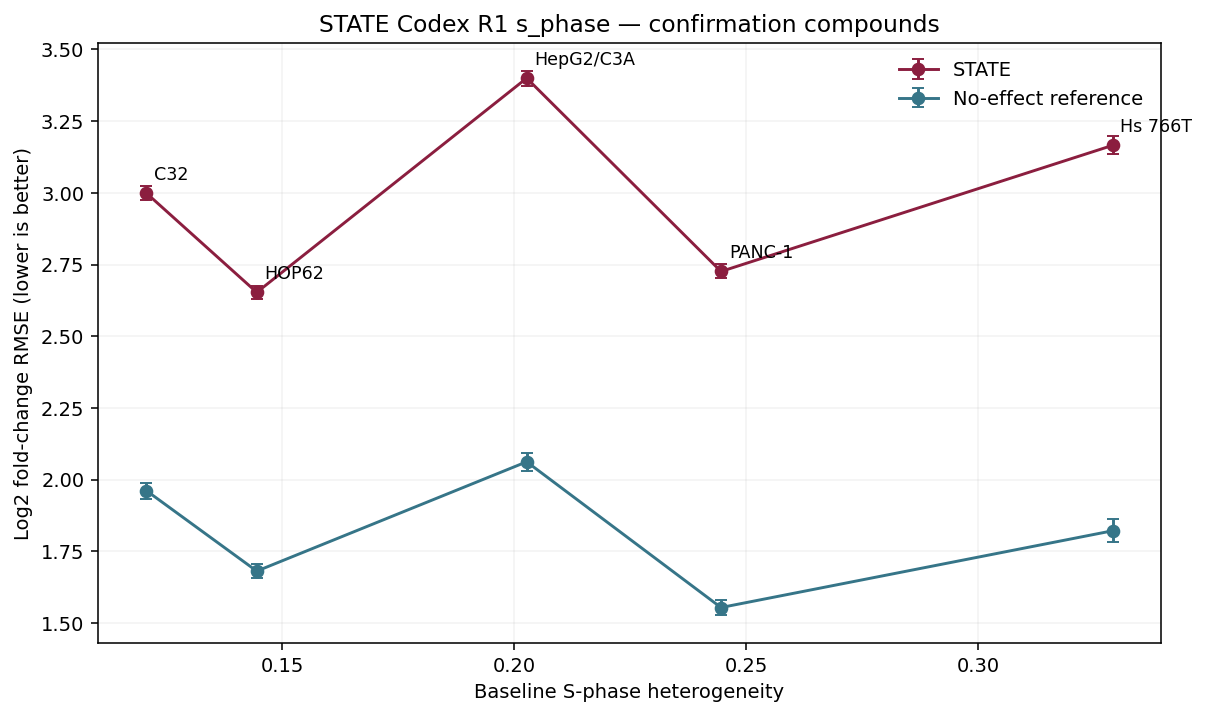

In [12]:
def context_spc(frame: pd.DataFrame, reps: int, seed: int) -> pd.DataFrame:
    compound_context = frame.groupby(["compound", "cell_line"], as_index=False).agg(
        state_lfc_rmse=("state_lfc_rmse", "mean"),
        identity_lfc_rmse=("identity_lfc_rmse", "mean"),
        distance=("distance", "first"),
        ccle_distance=("ccle_distance", "first"),
        n_conditions=("target", "nunique"),
    )
    compounds = sorted(compound_context["compound"].unique())
    rng = np.random.default_rng(seed)
    rows = []
    for cell, group in compound_context.groupby("cell_line"):
        indexed = group.set_index("compound")
        state_values = indexed.loc[compounds, "state_lfc_rmse"].to_numpy()
        reference_values = indexed.loc[compounds, "identity_lfc_rmse"].to_numpy()
        state_boot = np.empty(reps)
        reference_boot = np.empty(reps)
        for i in range(reps):
            sample = rng.integers(0, len(compounds), len(compounds))
            state_boot[i] = state_values[sample].mean()
            reference_boot[i] = reference_values[sample].mean()
        rows.append(
            {
                "cell_line": cell,
                "distance": group["distance"].iloc[0],
                "ccle_distance": group["ccle_distance"].iloc[0],
                "n_compounds": len(compounds),
                "n_conditions": int(group["n_conditions"].sum()),
                "state_rmse_mean": state_values.mean(),
                "state_rmse_ci_low": np.quantile(state_boot, 0.025),
                "state_rmse_ci_high": np.quantile(state_boot, 0.975),
                "identity_rmse_mean": reference_values.mean(),
                "identity_rmse_ci_low": np.quantile(reference_boot, 0.025),
                "identity_rmse_ci_high": np.quantile(reference_boot, 0.975),
            }
        )
    return pd.DataFrame(rows).sort_values("distance")

confirm['ccle_distance']=np.nan
curve = context_spc(confirm, BOOTSTRAP_REPS, RANDOM_SEED)
display(curve)
curve_rho = float(spearmanr(curve.distance, curve.state_rmse_mean).statistic)
print('Axis versus STATE mean-error Spearman correlation:', curve_rho)

fig, ax = plt.subplots(figsize=(8.5, 5.0), layout='constrained')
for metric, label, color in [('state', 'STATE', '#8B1E3F'), ('identity', 'No-effect reference', '#367588')]:
    means = curve[f'{metric}_rmse_mean'].to_numpy()
    low = curve[f'{metric}_rmse_ci_low'].to_numpy()
    high = curve[f'{metric}_rmse_ci_high'].to_numpy()
    ax.errorbar(curve.distance, means, yerr=np.vstack([means-low, high-means]),
                marker='o', capsize=3, color=color, label=label)
for row in curve.itertuples():
    ax.annotate(row.cell_line, (row.distance, row.state_rmse_mean),
                xytext=(4, 7), textcoords='offset points', fontsize=9)
ax.set(xlabel='Baseline S-phase heterogeneity',
       ylabel='Log2 fold-change RMSE (lower is better)',
       title='STATE Codex R1 s_phase — confirmation compounds')
ax.legend(frameon=False)
ax.grid(alpha=.15)
fig.savefig(OUTPUT_DIR / 's_phase_curve.png', dpi=160)
figure_buffer = BytesIO()
fig.savefig(figure_buffer, format='png', dpi=140, bbox_inches='tight')
display(Image(data=figure_buffer.getvalue()))
plt.close(fig)


In [13]:
sensitivity_rows = []
for dose, group in confirm.groupby('dose'):
    result = fit_within(group, 'state_lfc_rmse', CONTROLS)
    sensitivity_rows.append({'control': 'dose', 'subset': str(dose), **result})
for cell in sorted(confirm.cell_line.unique()):
    result = fit_within(confirm[confirm.cell_line.ne(cell)], 'state_lfc_rmse', CONTROLS)
    sensitivity_rows.append({'control': 'omit context', 'subset': cell, **result})
sensitivities = pd.DataFrame(sensitivity_rows)
display(sensitivities[['control', 'subset', 'estimate', 'se_cluster', 'n_rows', 'n_compounds']])

quintile_rows = confirm.copy()
quintile_rows['effect_bin'], effect_edges = pd.qcut(quintile_rows.identity_lfc_rmse, 5, labels=False, retbins=True, duplicates='drop')
quintile_rows['cells_bin'], cell_edges = pd.qcut(quintile_rows.n_cells, 5, labels=False, retbins=True, duplicates='drop')
quintile_controls = []
for prefix, column in [('effect_q', 'effect_bin'), ('cells_q', 'cells_bin')]:
    for level in range(1, 5):
        name = f'{prefix}_{level}'
        quintile_rows[name] = quintile_rows[column].eq(level).astype(float)
        quintile_controls.append(name)
quintile_fit = fit_within(quintile_rows, 'state_lfc_rmse', quintile_controls)
print('Reference-error cutpoints:', effect_edges)
print('Cell-count cutpoints:', cell_edges)
print('Rows retained in quintile adjustment:', len(quintile_rows))
display(pd.DataFrame([quintile_fit]))
display(quintile_rows.groupby(['effect_bin', 'cells_bin', 'cell_line'], observed=True).size().unstack('cell_line', fill_value=0))


,control,subset,estimate,se_cluster,n_rows,n_compounds
0,dose,0.05,0.088861,0.006069,1340,268
1,dose,0.5,0.090607,0.006194,1340,268
2,dose,5.0,0.107866,0.005666,1340,268
3,omit context,C32,0.096126,0.005135,3216,268
4,omit context,HOP62,0.067156,0.005349,3216,268
5,omit context,HepG2/C3A,0.124592,0.004568,3216,268
6,omit context,Hs 766T,0.131226,0.010512,3216,268
7,omit context,PANC-1,0.097994,0.004553,3216,268


Reference-error cutpoints: [0.63415208 1.48635944 1.67803462 1.8821652  2.11718487 4.24588553]
Cell-count cutpoints: [1.0000e+00 8.3180e+02 1.4722e+03 2.2870e+03 3.5452e+03 5.7193e+04]
Rows retained in quintile adjustment: 4020


,estimate,se_cluster,p_one_sided,p_two_sided,n_rows,n_targets,n_compounds,controls
0,0.106972,0.003657,1.938283e-188,3.876566e-188,4020,804,268,"[effect_q_1, effect_q_2, effect_q_3, effect_q_4, cells_q_1, cells_q_2, cells_q_3, cells_q_4]"


cell_line             C32  HOP62  HepG2/C3A  Hs 766T  PANC-1
effect_bin cells_bin                                        
0          2            0      0          0        0       1
           3            6     24         20       19      60
           4           37    171         19      149     298
1          1            0      0          1        0       0
           2            8     27         42       42      46
           3           80    160         36      102     151
           4           12     47          0       15      35
2          0            0      0          2        0       0
           1            9     21         71       40      26
           2          153    130         46       88      74
           3           30     64          2       14      21
           4            1      3          0        6       3
3          0            1      4         83       32       3
           1          162     79        135      114      33
           2           77     26          6       15      16
           3            3      2          0        2       4
           4            0      2          1        0       4
4          0          139     30        331      157      22
           1           80     11          9        8       5
           2            4      2          0        1       1
           3            2      0          0        0       1
           4            0      1          0        0       0

In [14]:
plate_values=replication.pivot(index='cell_name',columns='subset',values='std')
display(plate_values)
print('Odd/even S-phase rank correlation:',spearmanr(plate_values.odd,plate_values.even).statistic)
print('Full-QC/all-cell rank correlation:',spearmanr(plate_values.full_QC,plate_values['all']).statistic)

subset,all,even,full_QC,odd
cell_name,,,,
C32,0.120724,0.134481,0.121891,0.093208
HOP62,0.144538,0.163972,0.146427,0.111734
HepG2/C3A,0.202683,0.228171,0.182906,0.149987
Hs 766T,0.328889,0.386072,0.256622,0.234761
PANC-1,0.244544,0.286996,0.227007,0.164702


Odd/even S-phase rank correlation: 0.9999999999999999
Full-QC/all-cell rank correlation: 0.9999999999999999


In [15]:
hvg_rows=[]
for cell,stem in CONTEXT_FILES.items():
    z=compute_lfc_scores(DATA_DIR/f'acquisition/official_scores/{stem}_real_de.csv',DATA_DIR/f'acquisition/official_scores/{stem}_pred_de.csv').assign(cell_line=cell)
    hvg_rows.append(z)
hvg=pd.concat(hvg_rows,ignore_index=True)
discovery=conditions.drop(columns=list(hvg.columns.difference(['cell_line','target'])),errors='ignore').merge(hvg,on=['cell_line','target'],validate='one_to_one')
discovery=discovery[discovery.partition.eq('discovery')].copy()
discovery['log_n_de']=np.log1p(discovery.n_de)
discovery_fit,discovery_boot=fit_with_interval(discovery,'state_lfc_rmse',CONTROLS)
display(pd.DataFrame([{'model':'HVG discovery',**discovery_fit}]))


,model,estimate,se_cluster,p_one_sided,p_two_sided,n_rows,n_targets,n_compounds,controls,ci_low,ci_high
0,HVG discovery,0.121746,0.007827,7.433878e-55,1.486776e-54,1660,332,111,"[identity_lfc_rmse, log_n_de, log_n_cells]",0.105867,0.13656


## 6. What the agent decided, and why

Reject a monotonic S-phase heterogeneity degradation axis. The baseline measurement is reproducible across plates and QC filters, but the confirmation curve is not steadily worsening across the five ordered contexts.

In [16]:
decision_summary=pd.DataFrame([{'analysis':name,'estimate':fit_results[('confirmation',name)]['estimate'],'ci_low':fit_results[('confirmation',name)]['ci_low'],'ci_high':fit_results[('confirmation',name)]['ci_high']} for name in ['state_raw','state_adjusted','identity_raw']])
display(decision_summary)
print('Ordered context-mean error steps:',np.diff(curve.state_rmse_mean.to_numpy()))
print('Monotonically increasing error:',bool(np.all(np.diff(curve.state_rmse_mean.to_numpy())>=0)))
print('Paired STATE-minus-reference slope:',paired_difference,'95% interval:',paired_ci)
display(sensitivities[['control','subset','estimate']])
for name,frame in {'axis.csv':primary,'per_condition_scores.csv':conditions,'regressions.csv':fits,'curve.csv':curve,'sensitivity.csv':sensitivities,'baseline_features.csv':heterogeneity,'baseline_replication.csv':replication}.items():frame.to_csv(OUTPUT_DIR/name,index=False)
execution_record={'completed':True,'host':platform.node(),'python':platform.python_version(),'elapsed_seconds':time.time()-STARTED,'sources':download_receipts,'external_custom_code':False,'derived_inputs_read':False,'model_inference_performed':False,'bootstrap_repetitions':BOOTSTRAP_REPS,'seed':RANDOM_SEED,'conditions':len(conditions)}
(OUTPUT_DIR/'execution_record.json').write_text(json.dumps(execution_record,indent=2))


,analysis,estimate,ci_low,ci_high
0,state_raw,0.080561,0.070037,0.091276
1,state_adjusted,0.095149,0.085573,0.104637
2,identity_raw,-0.038704,-0.051348,-0.025934


Ordered context-mean error steps: [-0.34665428  0.74705663 -0.67417817  0.43966411]
Monotonically increasing error: False
Paired STATE-minus-reference slope: 0.11926556628890109 95% interval: [0.11218131 0.12600389]


,control,subset,estimate
0,dose,0.05,0.088861
1,dose,0.5,0.090607
2,dose,5.0,0.107866
3,omit context,C32,0.096126
4,omit context,HOP62,0.067156
5,omit context,HepG2/C3A,0.124592
6,omit context,Hs 766T,0.131226
7,omit context,PANC-1,0.097994


15696